In [3]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "koreanize-matplotlib==0.1.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


스타트업 점수 VQE 선택 비트: [0 1 1 1 1 0]
기대 QUBO 비용: 0.08790053079540808
선택 목적값 / 완전탐색 최솟값 / 차이: 0.08535522405121182 0.08506466185020234 0.00029056220100948105
선택 상태 확률: 0.5361169955945024
회귀 계수: [0.5 1.  0. ]
격자 VQE MSE / 연속 최소제곱 MSE: 0.0853552240512117 0.06285919540229884
AlphaTech  | 압축 입력 +0.0370 | 정답 88 | 근사 84.30
BetaSoft   | 압축 입력 +0.0370 | 정답 83 | 근사 84.30
GreenLoop  | 압축 입력 -0.0741 | 정답 80 | 근사 83.41
DeltaAI    | 압축 입력 -0.0370 | 정답 85 | 근사 83.70
NeoHealth  | 압축 입력 +0.0000 | 정답 82 | 근사 84.00
FinHive    | 압축 입력 +0.0370 | 정답 84 | 근사 84.30
점수 단위 RMSE: 2.3372493104668037
스타트업 점수 근삿값: 85.78


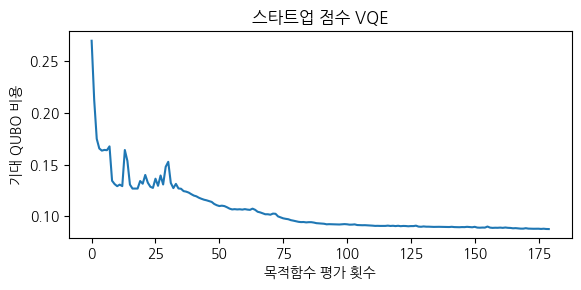

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib
from itertools import product
from qiskit.circuit.library import real_amplitudes
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import Statevector
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

# 1. 입력 데이터
X = np.array([[9,8,5],[7,7,8],[6,9,4],[8,6,6],[9,5,7],[5,8,9]])
scores = np.array([88,83,80,85,82,84])

# 2. 특성 압축과 점수 정규화
center, scale = X.mean(axis=0), float(X.max())
u = ((X-center)/scale).mean(axis=1)
y_min, y_range = scores.min(), float(np.ptp(scores))
x = u
y = (scores - y_min) / y_range

# 3. 계수 비트와 MSE 목적함수
phi = np.column_stack([np.ones(len(x)), x, x*x])
base = np.array([0.0, -0.5, -0.5])
step = np.array([0.25, 0.5, 0.5])
B = np.zeros((3, 6))
for j in range(3):
    B[j, 2*j:2*j+2] = step[j] * np.array([1, 2])
A = phi @ B
r = phi @ base-y
problem = QuadraticProgram()
for j in range(6):
    problem.binary_var(f'b{j}')
problem.minimize(constant=float(r@r/len(y)),
                 linear=2*A.T@r/len(y), quadratic=A.T@A/len(y))

# 4. QUBO와 Ising 해밀토니안
converter = QuadraticProgramToQubo()
qubo = converter.convert(problem)
H, offset = qubo.to_ising()
n = qubo.get_num_vars()
# 모든 기저상태에서 QUBO 목적값과 Ising 에너지의 대응을 확인합니다.
diagonal = np.real(np.diag(H.to_matrix())) + offset
for i, value in enumerate(diagonal):
    bits = np.array([(i >> j) & 1 for j in range(n)])
    assert np.isclose(value, qubo.objective.evaluate(bits))
# 5. 안자츠와 고전 최적화기
ansatz = real_amplitudes(n, reps=2, entanglement='linear')
history = []
vqe = VQE(StatevectorEstimator(), ansatz, COBYLA(maxiter=180),
          initial_point=np.array([0.5479120971119267, -0.12224312049589536, 0.7171958398227649, 0.3947360581187278, -0.8116453042247009, 0.9512447032735118, 0.5222794039807059, 0.5721286105539076, -0.7437727346489083, -0.09922812420886573, -0.25840395153483753, 0.8535299776972036, 0.2877302401613291, 0.64552322654166, -0.11317160234533774, -0.5455225564304462, 0.1091695740316696, -0.8723654877916494])[:ansatz.num_parameters],
          callback=lambda k, p, value, meta: history.append(float(value)+offset))
# 6. VQE 실행과 상태 확률 계산
result = vqe.compute_minimum_eigenvalue(H)
probabilities = Statevector.from_instruction(
    ansatz.assign_parameters(result.optimal_parameters)).probabilities()
# 7. 선택 복원과 정확 최솟값 검증
# 실행 가능한 상태 중 확률이 가장 큰 상태를 선택합니다.
candidates = []
for i, p in enumerate(probabilities):
    bits = np.array([(i >> j) & 1 for j in range(n)])
    original_bits = np.asarray(converter.interpret(bits))
    if problem.is_feasible(original_bits):
        candidates.append((float(p), original_bits))
probability, chosen = max(candidates, key=lambda item: item[0])
value = float(problem.objective.evaluate(chosen))
exact = min(
    float(problem.objective.evaluate(np.asarray(bits)))
    for bits in product((0, 1), repeat=problem.get_num_vars())
    if problem.is_feasible(np.asarray(bits))
)
print("스타트업 점수 VQE", '선택 비트:', chosen.astype(int))
print('기대 QUBO 비용:', float(result.eigenvalue.real)+offset)
print('선택 목적값 / 완전탐색 최솟값 / 차이:', value, exact, value-exact)
print('선택 상태 확률:', probability)

coeff = base + B @ chosen
prediction = phi @ coeff
mse = np.mean((prediction - y) ** 2)
assert np.isclose(problem.objective.evaluate(chosen), mse)
classical = np.linalg.lstsq(phi, y, rcond=None)[0]
print('회귀 계수:', coeff)
print('격자 VQE MSE / 연속 최소제곱 MSE:',
      mse, np.mean((phi @ classical - y) ** 2))

# 8. 업무 결과 출력과 저장
np.savez('startup_model.npz', coeff=coeff, center=center, scale=scale,
         y_min=y_min, y_range=y_range)

company_names = ['AlphaTech', 'BetaSoft', 'GreenLoop', 'DeltaAI', 'NeoHealth', 'FinHive']
# 저장한 모델을 불러와 예측값과 오차를 계산합니다.
with np.load('startup_model.npz') as model:
    features = np.array([[9,8,5],[7,7,8],[6,9,4],[8,6,6],[9,5,7],[5,8,9]])
    actual_scores = np.array([88,83,80,85,82,84])
    u = ((features-model['center'])/model['scale']).mean(axis=1)
    a = model['coeff']
    fitted = model['y_min']+model['y_range']*(a[0]+a[1]*u+a[2]*u*u)
    for name, compressed, actual, estimate in zip(company_names, u, actual_scores, fitted):
        print(f'{name:10s} | 압축 입력 {compressed:+.4f} | 정답 {actual} | 근사 {estimate:.2f}')
    print('점수 단위 RMSE:', np.sqrt(np.mean((fitted-actual_scores)**2)))

with np.load('startup_model.npz') as m:
    new_data = np.array([9.0, 9.0, 9.0])
    if new_data.shape != (3,) or not np.isfinite(new_data).all() or np.any((new_data<0)|(new_data>10)):
        raise ValueError('세 특성에 각각 0~10 사이의 숫자를 입력하세요.')
    u = np.mean((new_data-m['center'])/m['scale'])
    a = m['coeff']
    score = float(m['y_min']+m['y_range']*(a[0]+a[1]*u+a[2]*u*u))
    print(f'스타트업 점수 근삿값: {score:.2f}')

title = "스타트업 점수 VQE"
plt.figure(figsize=(6, 3)); plt.plot(history)
plt.title(title); plt.xlabel('목적함수 평가 횟수'); plt.ylabel('기대 QUBO 비용')
plt.tight_layout(); plt.savefig(title+'.png', dpi=120); plt.show(); plt.close()